<a href="https://colab.research.google.com/github/predowss/passo-firme-visao/blob/main/notebooks/02_treino_rodada2_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Passo Firme — treino do detector de barreiras de calçada (YOLO26)

Disciplina **Applied Computer Vision** · Global Solution 2026.2 · CitizenTech

Este notebook treina um YOLO26 sob medida para achar `buraco`, `desnivel` e `obstaculo` em fotos de calçadas de São Paulo, avalia o resultado e gera as figuras do relatório.

**Rodada 2 (16/11).** A rodada 1 mostrou que a validação misturava imagens de SP e do dataset aberto, e que o modelo acertava 0,94 de mAP50 nas abertas e só 0,20 nas de SP. Nesta rodada:
- o dataset é o mesmo (versão 1 do Roboflow);
- a validação usa **só imagens de SP**, e as do dataset aberto ficam reservadas para medir a diferença entre os dois;
- entra uma variante com **2 classes** (`dano_no_piso` = buraco + desnível, e `obstaculo`).

**Antes de rodar**
1. *Ambiente de execução → Alterar o tipo de ambiente de execução →* **GPU T4**.
2. Clique no ícone de chave (**Secrets**) na barra lateral e ligue o **acesso deste notebook** ao segredo `ROBOFLOW_API_KEY`. A chave nunca fica escrita no código.
3. Nada para preencher: workspace, projeto e versão já estão certos.
4. *Ambiente de execução →* **Executar tudo**. Leva cerca de 30 minutos; deixem a aba aberta. No fim, o navegador baixa os dois modelos e um zip com os resultados.

**Ao terminar:** *Arquivo → Salvar uma cópia no GitHub* (`notebooks/02_treino_rodada2_colab.ipynb`), com as saídas.

In [1]:
!nvidia-smi

Mon Nov 16 01:26:40 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
%pip install -q "ultralytics>=8.4.0" roboflow
import ultralytics
ultralytics.checks()

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/112.6 GB disk)


## 1. Baixar o dataset do Roboflow

A versão junta as imagens de calçadas de São Paulo baixadas do Mapillary (arquivos `sp_<bairro>_<id>.jpg`, anotadas pelo grupo) e as 105 imagens do dataset aberto *Sidewalk obstacles* (Blindspot), com as classes de origem reagrupadas em `obstaculo` pelo *Modify Classes*. O teste tem só imagens de SP. O formato `yolov8` é o mesmo `.txt` que o YOLO26 lê.

In [3]:
from google.colab import userdata
from roboflow import Roboflow

WORKSPACE = "pedros-workspace-md4aw"   # aparece na URL: app.roboflow.com/<workspace>/<projeto>
PROJETO = "passo-firme-calcadas"   # nome do projeto no Roboflow
VERSAO = 1                         # versão v1-sp-blindspot

rf = Roboflow(api_key=userdata.get("ROBOFLOW_API_KEY"))
dataset = rf.workspace(WORKSPACE).project(PROJETO).version(VERSAO).download("yolov8", location="/content/dataset", overwrite=True)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/dataset in yolov8:: 100%|██████████| 575/575 [00:00<00:00, 682.23it/s]


In [4]:
import yaml
from pathlib import Path

def preparar_yaml(pasta):
    """O data.yaml exportado às vezes traz caminhos relativos que quebram no Colab: fixamos os absolutos."""
    arquivo = Path(pasta) / "data.yaml"
    cfg = yaml.safe_load(arquivo.read_text())
    cfg["path"] = str(pasta)
    cfg["train"], cfg["val"] = "train/images", "valid/images"
    if (Path(pasta) / "test" / "images").exists():
        cfg["test"] = "test/images"
    else:
        cfg.pop("test", None)
    arquivo.write_text(yaml.safe_dump(cfg, allow_unicode=True))
    return str(arquivo), cfg

DATA, cfg = preparar_yaml(dataset.location)
SPLIT = "test" if "test" in cfg else "val"          # conjunto usado na avaliação final
PASTA_TESTE = "test" if SPLIT == "test" else "valid"
NOMES = cfg["names"] if isinstance(cfg["names"], list) else [cfg["names"][k] for k in sorted(cfg["names"])]
print("Classes:", NOMES, "| avaliação final em:", SPLIT)

Classes: ['buraco', 'desnivel', 'obstaculo'] | avaliação final em: test


In [5]:
import shutil

# Validação só com SP: as imagens do dataset aberto que estavam na validação vão para uma reserva,
# fora do treino e da escolha do modelo, usada só na seção 6 para medir SP x dataset aberto.
reserva = Path(dataset.location) / "aberto_reserva"
for sub in ["images", "labels"]:
    (reserva / sub).mkdir(parents=True, exist_ok=True)
movidas = 0
for img in sorted((Path(dataset.location) / "valid" / "images").glob("*")):
    if not img.name.lower().startswith("sp_"):
        rot = Path(dataset.location) / "valid" / "labels" / (img.stem + ".txt")
        shutil.move(str(img), reserva / "images" / img.name)
        if rot.exists():
            shutil.move(str(rot), reserva / "labels" / rot.name)
        movidas += 1
for cache in Path(dataset.location).rglob("*.cache"):
    cache.unlink()
print(f"{movidas} imagens do dataset aberto saíram da validação e foram para a reserva.")

16 imagens do dataset aberto saíram da validação e foram para a reserva.


In [6]:
import pandas as pd
from collections import Counter

linhas = []
for rotulo_conjunto, pasta in [("treino", "train"), ("validação", "valid"), ("teste", "test"), ("reserva aberta", "aberto_reserva")]:
    base = Path(dataset.location) / pasta
    if not base.exists():
        continue
    contagem, nulas = Counter(), 0
    imagens = [p for p in (base / "images").glob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]
    for img in imagens:
        rot = base / "labels" / (img.stem + ".txt")
        anot = [l for l in rot.read_text().splitlines() if l.strip()] if rot.exists() else []
        nulas += not anot
        for l in anot:
            contagem[int(float(l.split()[0]))] += 1
    linhas.append({"conjunto": rotulo_conjunto, "imagens": len(imagens), "sem barreira": nulas,
                   **{n: contagem.get(i, 0) for i, n in enumerate(NOMES)}})

tabela_dataset = pd.DataFrame(linhas)
tabela_dataset   # vai para o PDF (seção Metodologia)

,conjunto,imagens,sem barreira,buraco,desnivel,obstaculo
0,treino,216,21,58,52,463
1,validação,22,1,5,17,24
2,teste,31,5,25,10,36
3,reserva aberta,16,0,0,0,66


## 2. Variante com 2 classes

Buraco e desnível são defeitos do piso com forma irregular, poucos exemplos (58 buracos e 52 desníveis no treino) e fronteira difícil entre um e outro. A variante junta os dois em `dano_no_piso`, o que dobra os exemplos da classe. É a mesma imagem e a mesma caixa: só muda o rótulo.

In [7]:
import shutil

DATASET_2C = Path("/content/dataset_2c")
if DATASET_2C.exists():
    shutil.rmtree(DATASET_2C)
shutil.copytree(dataset.location, DATASET_2C)
for cache in DATASET_2C.rglob("*.cache"):
    cache.unlink()

nova_classe = {}
for i, nome in enumerate(NOMES):
    nova_classe[i] = 1 if nome == "obstaculo" else 0      # buraco e desnivel -> 0 (dano_no_piso)
for rot in DATASET_2C.rglob("labels/*.txt"):
    linhas = []
    for l in rot.read_text().splitlines():
        if l.strip():
            partes = l.split()
            partes[0] = str(nova_classe[int(float(partes[0]))])
            linhas.append(" ".join(partes))
    rot.write_text("\n".join(linhas) + ("\n" if linhas else ""))

cfg_2c = {"path": str(DATASET_2C), "train": "train/images", "val": "valid/images", "test": "test/images",
          "names": ["dano_no_piso", "obstaculo"]}
DATA_2C = str(DATASET_2C / "data.yaml")
Path(DATA_2C).write_text(yaml.safe_dump(cfg_2c, allow_unicode=True))
print("Variante pronta:", cfg_2c["names"])

Variante pronta: ['dano_no_piso', 'obstaculo']


## 3. Experimentos A e C2 — YOLO26n

Ajuste fino (*transfer learning*) a partir dos pesos pré-treinados no COCO. **A** treina as 3 classes; **C2** treina a variante com 2 classes. A resolução fica em 640: na rodada 1, 960 não melhorou e deixou o modelo mais lento na CPU.

| Parâmetro | Valor |
| --- | --- |
| Modelo base | `yolo26n.pt` (COCO) |
| Tamanho da imagem | 640 |
| Épocas | até 100, com parada antecipada após 30 sem melhora (`patience`; a validação é pequena e oscila) |
| Lote | 16 |
| Semente | 42 |
| Aumento de dados | padrão do Ultralytics: mosaico, variação de cor (HSV), escala, translação e espelhamento horizontal. Sem espelhamento vertical: a calçada nunca aparece de cabeça para baixo. |

In [8]:
from ultralytics import YOLO

IMG = 640
comum = dict(imgsz=IMG, epochs=100, patience=30, batch=16, seed=42,
             project="/content/runs", exist_ok=True, plots=True)

YOLO("yolo26n.pt").train(data=DATA, name="A_yolo26n", **comum)
A_BEST = "/content/runs/A_yolo26n/weights/best.pt"

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=A_yolo26n, nbs=64, nms=None, opset=None, optimize=False, optim

In [9]:
YOLO("yolo26n.pt").train(data=DATA_2C, name="C2_yolo26n_2classes", **comum)
C2_BEST = "/content/runs/C2_yolo26n_2classes/weights/best.pt"

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_2c/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=C2_yolo26n_2classes, nbs=64, nms=None, opset=None, optimize

A_yolo26n


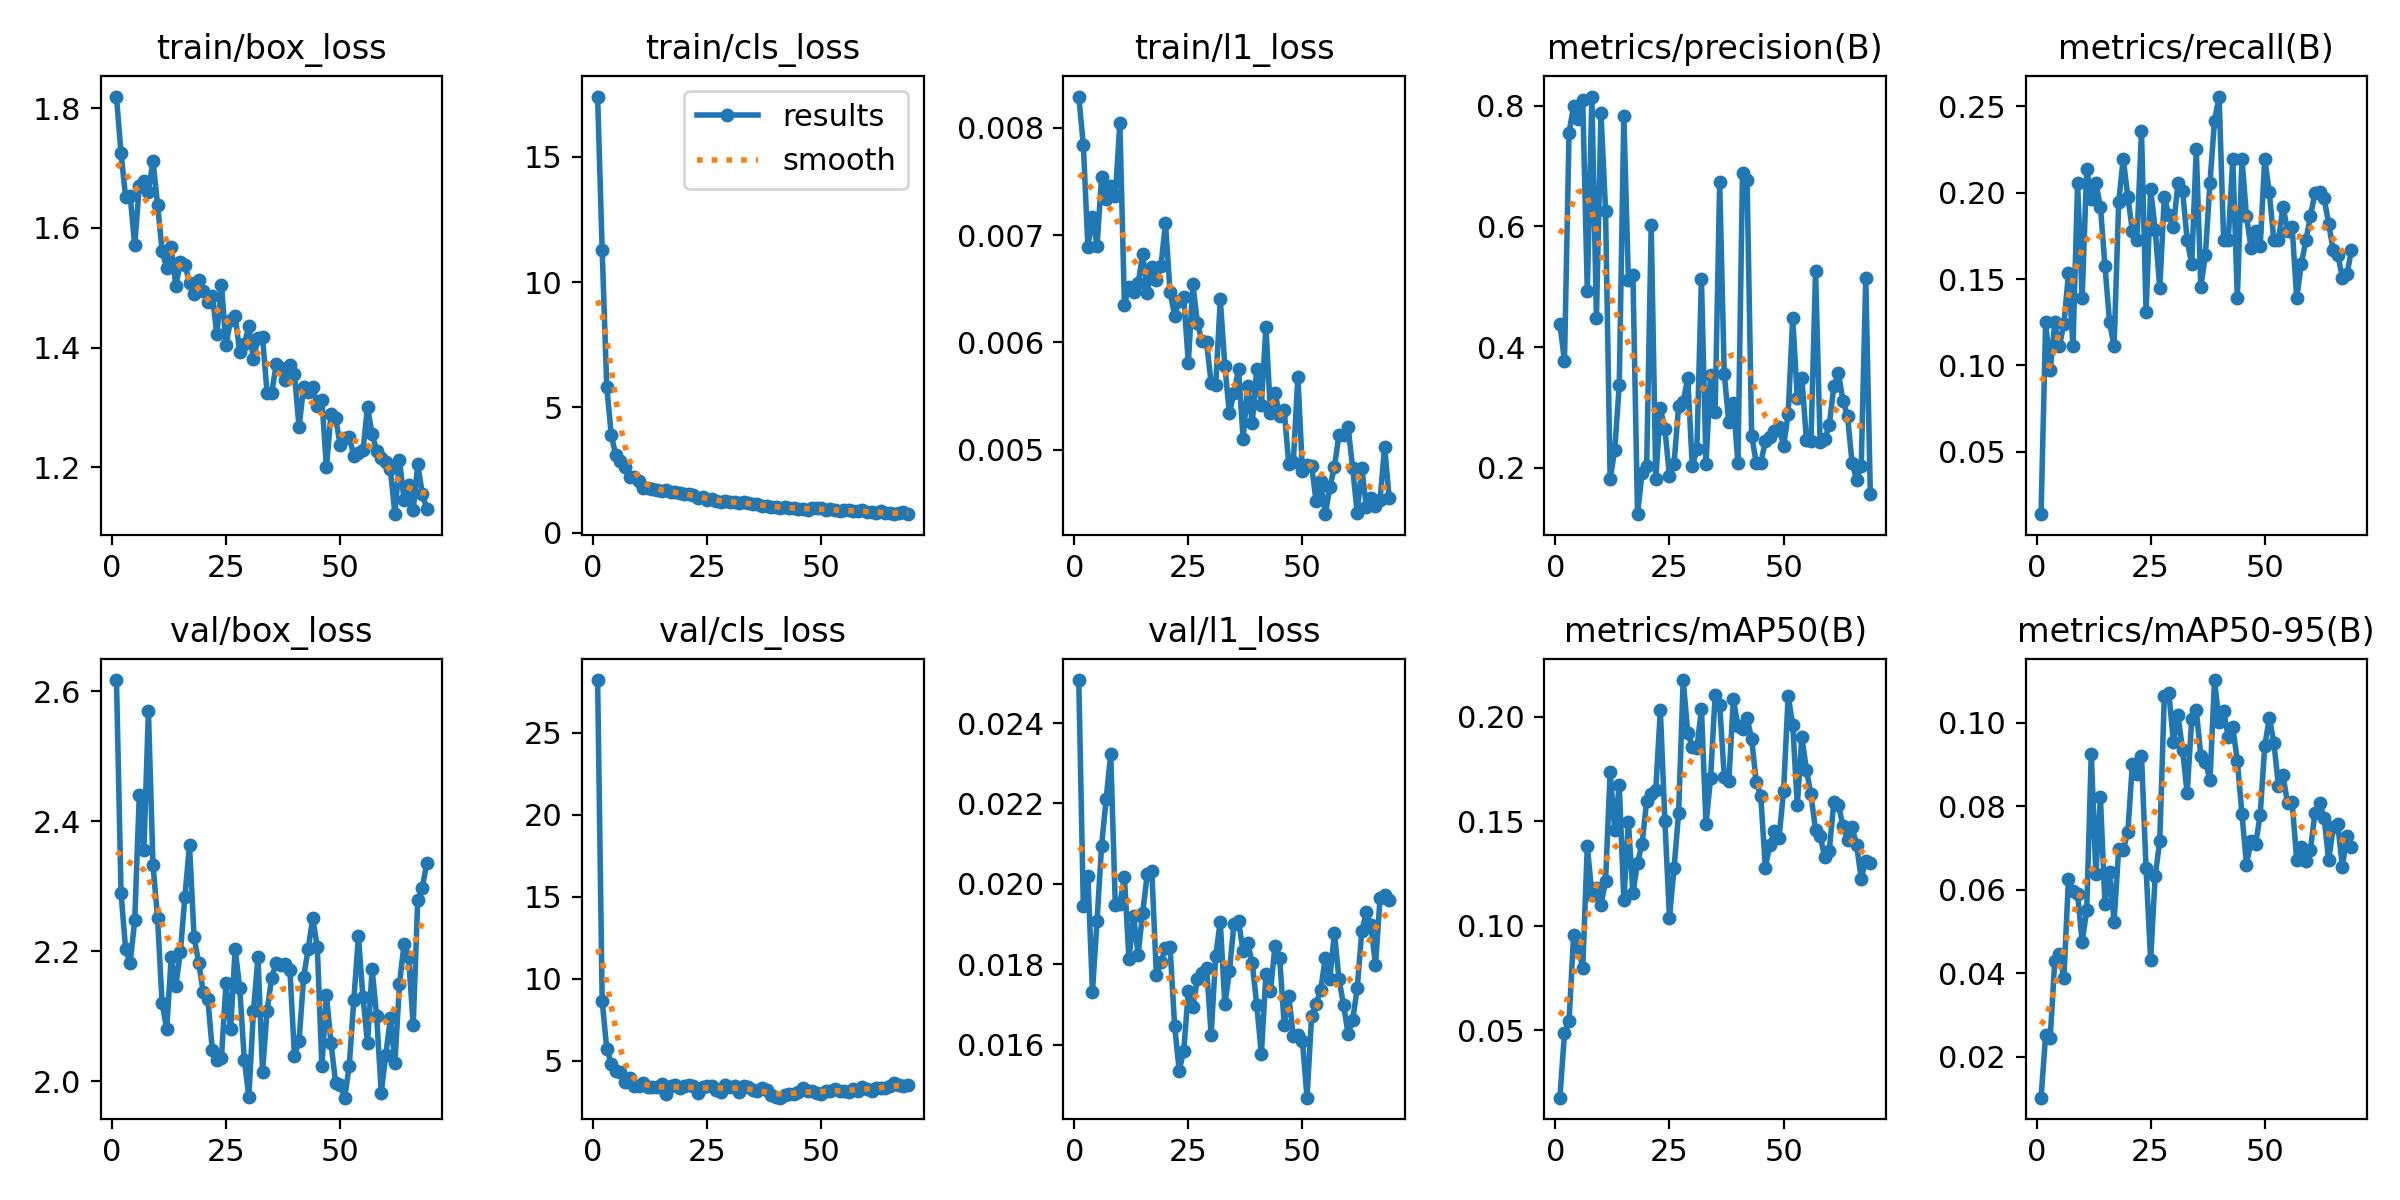

C2_yolo26n_2classes


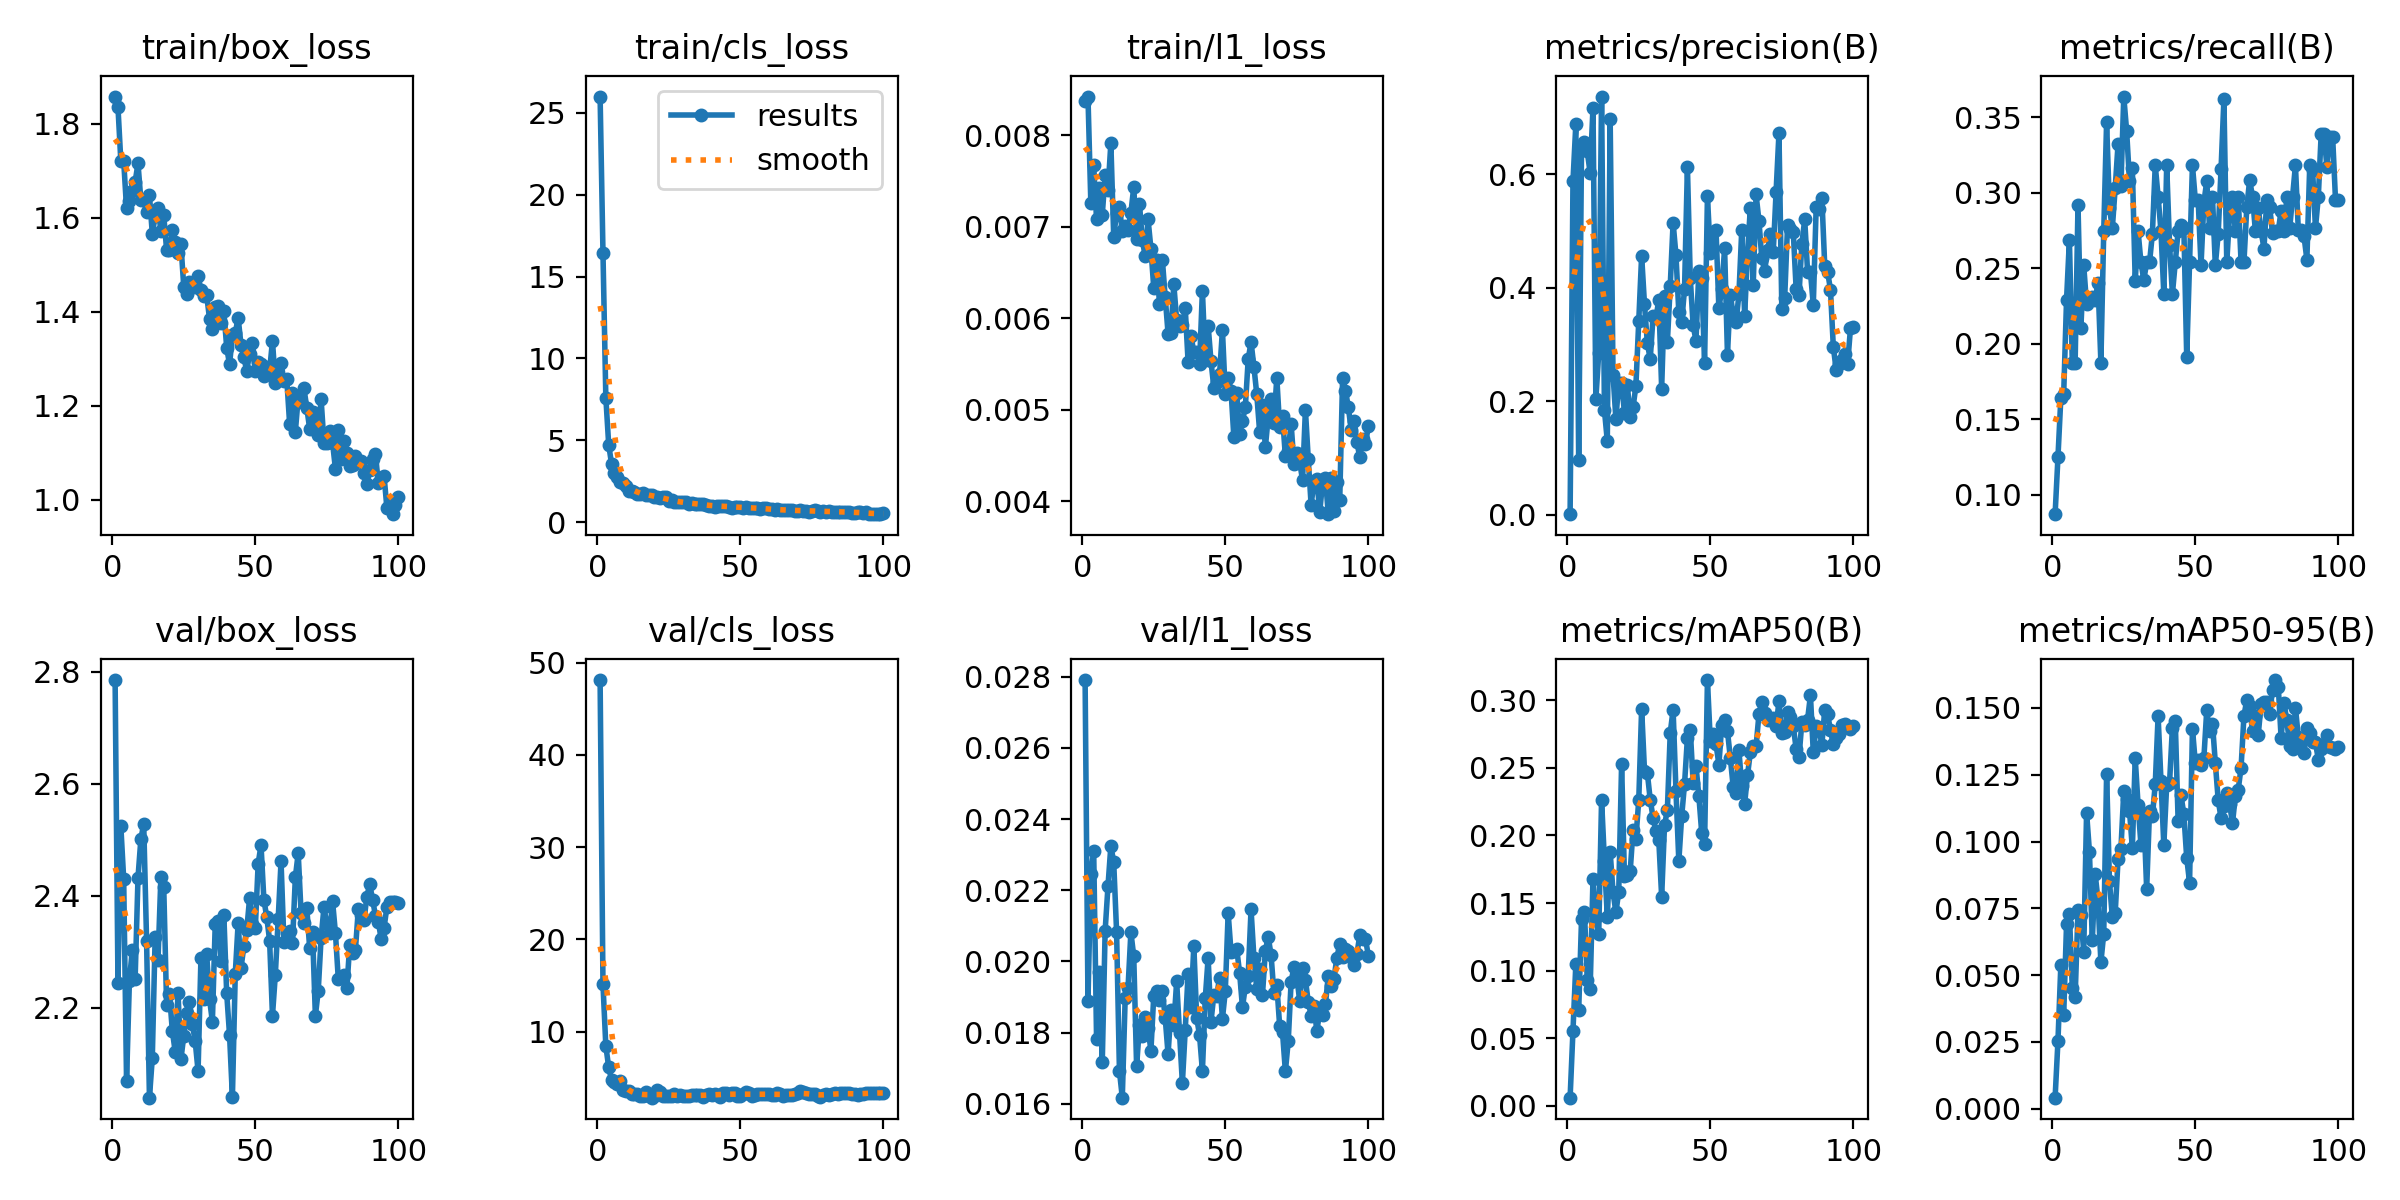

In [10]:
from IPython.display import Image, display
for nome in ["A_yolo26n", "C2_yolo26n_2classes"]:   # curvas de perda e métricas por época
    print(nome)
    display(Image(f"/content/runs/{nome}/results.png", width=950))

## 4. Avaliação no conjunto de teste

O teste tem só fotos de ruas de SP que nenhum modelo viu, separadas antes do treino.
- **Precisão:** das caixas que o modelo desenhou, quantas estavam certas.
- **Recall:** das barreiras que existiam, quantas o modelo achou. Para quem anda com bengala ou cadeira de rodas, um buraco não detectado custa mais que um falso alarme.
- **mAP50:** média, entre as classes, da área sob a curva precisão × recall, contando como acerto a caixa com IoU ≥ 0,5.
- **mAP50-95:** a mesma média, exigindo caixas cada vez mais justas (IoU de 0,5 a 0,95).

Para comparar A e C2 de forma justa, a linha `dano_no_piso (A, juntando)` avalia o próprio modelo A tratando buraco e desnível como uma classe só.

In [11]:
def avaliar(pesos, nome, data, split="test"):
    m = YOLO(pesos).val(data=data, split=split, imgsz=IMG, batch=16,
                        project="/content/runs", name=nome, exist_ok=True)
    por_classe = []
    for i, c in enumerate(m.box.ap_class_index):
        p, r, ap50, ap = m.box.class_result(i)
        por_classe.append({"classe": m.names[int(c)], "precisão": p, "recall": r, "mAP50": ap50, "mAP50-95": ap})
    geral = {"precisão": m.box.mp, "recall": m.box.mr, "mAP50": m.box.map50, "mAP50-95": m.box.map,
             "ms por imagem (GPU T4)": m.speed["inference"]}
    return pd.DataFrame(por_classe).round(3), geral

tabelaA, geralA = avaliar(A_BEST, "A_teste", DATA)
tabelaC2, geralC2 = avaliar(C2_BEST, "C2_teste", DATA_2C)

# o modelo A avaliado como se tivesse 2 classes: previsões de buraco e desnivel viram dano_no_piso
from ultralytics.utils.metrics import ap_per_class
import numpy as np, torch
from ultralytics.utils.metrics import box_iou

def avaliar_A_juntando():
    modelo = YOLO(A_BEST)
    juntar = lambda c: 1 if NOMES[int(c)] == "obstaculo" else 0
    tp, conf, pred_cls, target_cls = [], [], [], []
    limiares = np.linspace(0.5, 0.95, 10)
    for img in sorted((DATASET_2C / "test" / "images").glob("*")):
        r = modelo.predict(str(img), imgsz=IMG, conf=0.001, verbose=False)[0]
        h, w = r.orig_shape
        rot = DATASET_2C / "test" / "labels" / (img.stem + ".txt")
        reais = []
        if rot.exists():
            for l in rot.read_text().splitlines():
                if l.strip():
                    c, xc, yc, bw, bh = map(float, l.split()[:5])
                    reais.append([int(c), (xc - bw / 2) * w, (yc - bh / 2) * h, (xc + bw / 2) * w, (yc + bh / 2) * h])
        reais = np.array(reais).reshape(-1, 5)
        caixas = r.boxes.xyxy.cpu().numpy()
        classes = np.array([juntar(c) for c in r.boxes.cls.tolist()])
        confs = r.boxes.conf.cpu().numpy()
        acerto = np.zeros((len(caixas), len(limiares)), dtype=bool)
        if len(caixas) and len(reais):
            ious = box_iou(torch.tensor(reais[:, 1:]), torch.tensor(caixas)).numpy()
            for k, lim in enumerate(limiares):
                usados = set()
                for j in np.argsort(-confs):
                    candidatos = [(ious[i, j], i) for i in range(len(reais))
                                  if i not in usados and reais[i, 0] == classes[j] and ious[i, j] >= lim]
                    if candidatos:
                        usados.add(max(candidatos)[1])
                        acerto[j, k] = True
        tp.append(acerto); conf.append(confs); pred_cls.append(classes); target_cls.append(reais[:, 0])
    res = ap_per_class(np.concatenate(tp), np.concatenate(conf), np.concatenate(pred_cls), np.concatenate(target_cls),
                       names={0: "dano_no_piso", 1: "obstaculo"})
    p, r, ap = res[2], res[3], res[5]
    return pd.DataFrame([{"classe": n + " (A, juntando)", "precisão": p[i], "recall": r[i], "mAP50": ap[i, 0], "mAP50-95": ap[i].mean()}
                         for i, n in enumerate(["dano_no_piso", "obstaculo"])]).round(3)

try:
    tabelaA_juntando = avaliar_A_juntando()
except Exception as erro:   # se a conta manual falhar, o resto do notebook continua
    print("Não foi possível avaliar o A juntando as classes:", erro)
    tabelaA_juntando = pd.DataFrame(columns=["classe", "precisão", "recall", "mAP50", "mAP50-95"])
comparacao_classes = pd.concat([tabelaA_juntando, tabelaC2.assign(classe=tabelaC2.classe + " (C2)")], ignore_index=True)
print("Teste por classe, A (3 classes):"); display(tabelaA)
print("A x C2 com as mesmas 2 classes:"); display(comparacao_classes)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3904.6±730.6 MB/s, size: 342.0 KB)
val: Scanning /content/dataset/test/labels... 31 images, 5 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 31/31 2.1Kit/s 0.0s
val: New cache created: /content/dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.6it/s 1.2s
                   all         31         71      0.149      0.199      0.107     0.0497
                buraco         16         25      0.114       0.12     0.0741     0.0203
              desnivel         10         10      0.105        0.2     0.0291     0.0159
             obstaculo         20         36      0.228      0.278      0.217      0.113
Speed: 2.4ms preprocess, 8.2ms inference, 0.0ms loss, 2.8ms postprocess per image
Resul

,classe,precisão,recall,mAP50,mAP50-95
0,buraco,0.114,0.120,0.074,0.020
1,desnivel,0.105,0.200,0.029,0.016
2,obstaculo,0.228,0.278,0.217,0.113


A x C2 com as mesmas 2 classes:


,classe,precisão,recall,mAP50,mAP50-95
0,"dano_no_piso (A, juntando)",0.117,0.143,0.060,0.015
1,"obstaculo (A, juntando)",0.250,0.351,0.210,0.105
2,dano_no_piso (C2),0.159,0.086,0.033,0.010
3,obstaculo (C2),0.384,0.333,0.305,0.184


A_teste


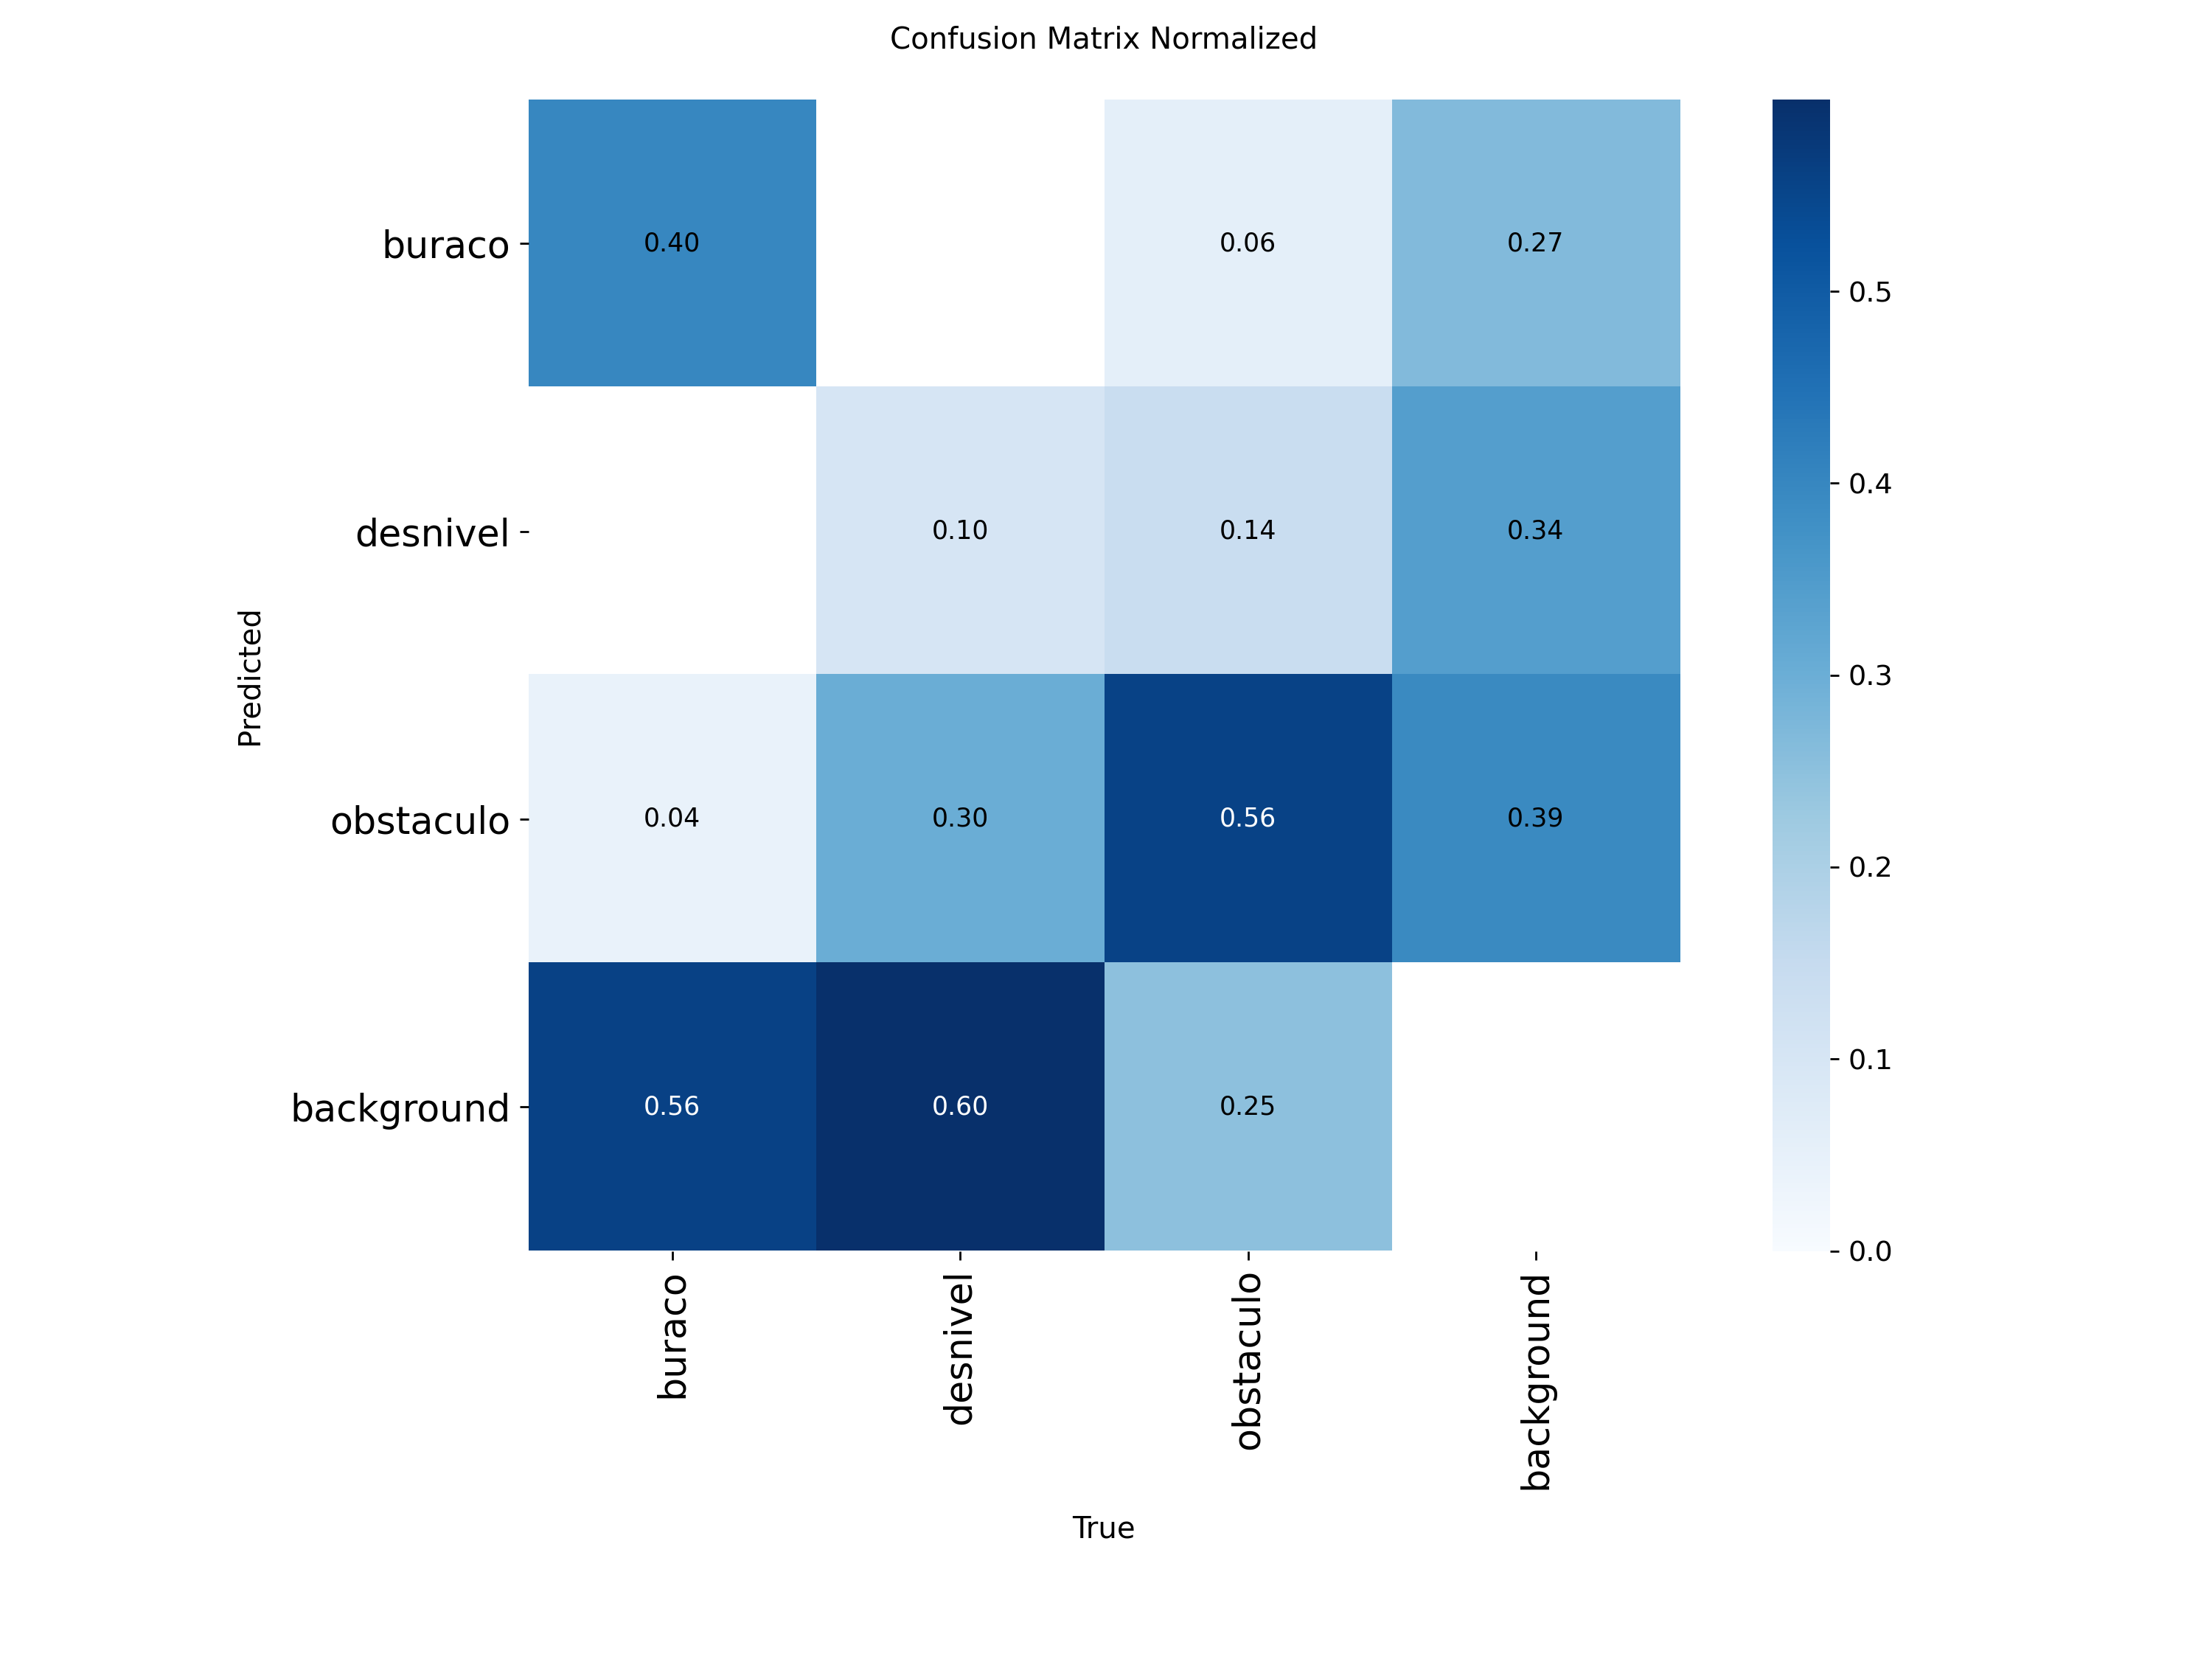

C2_teste


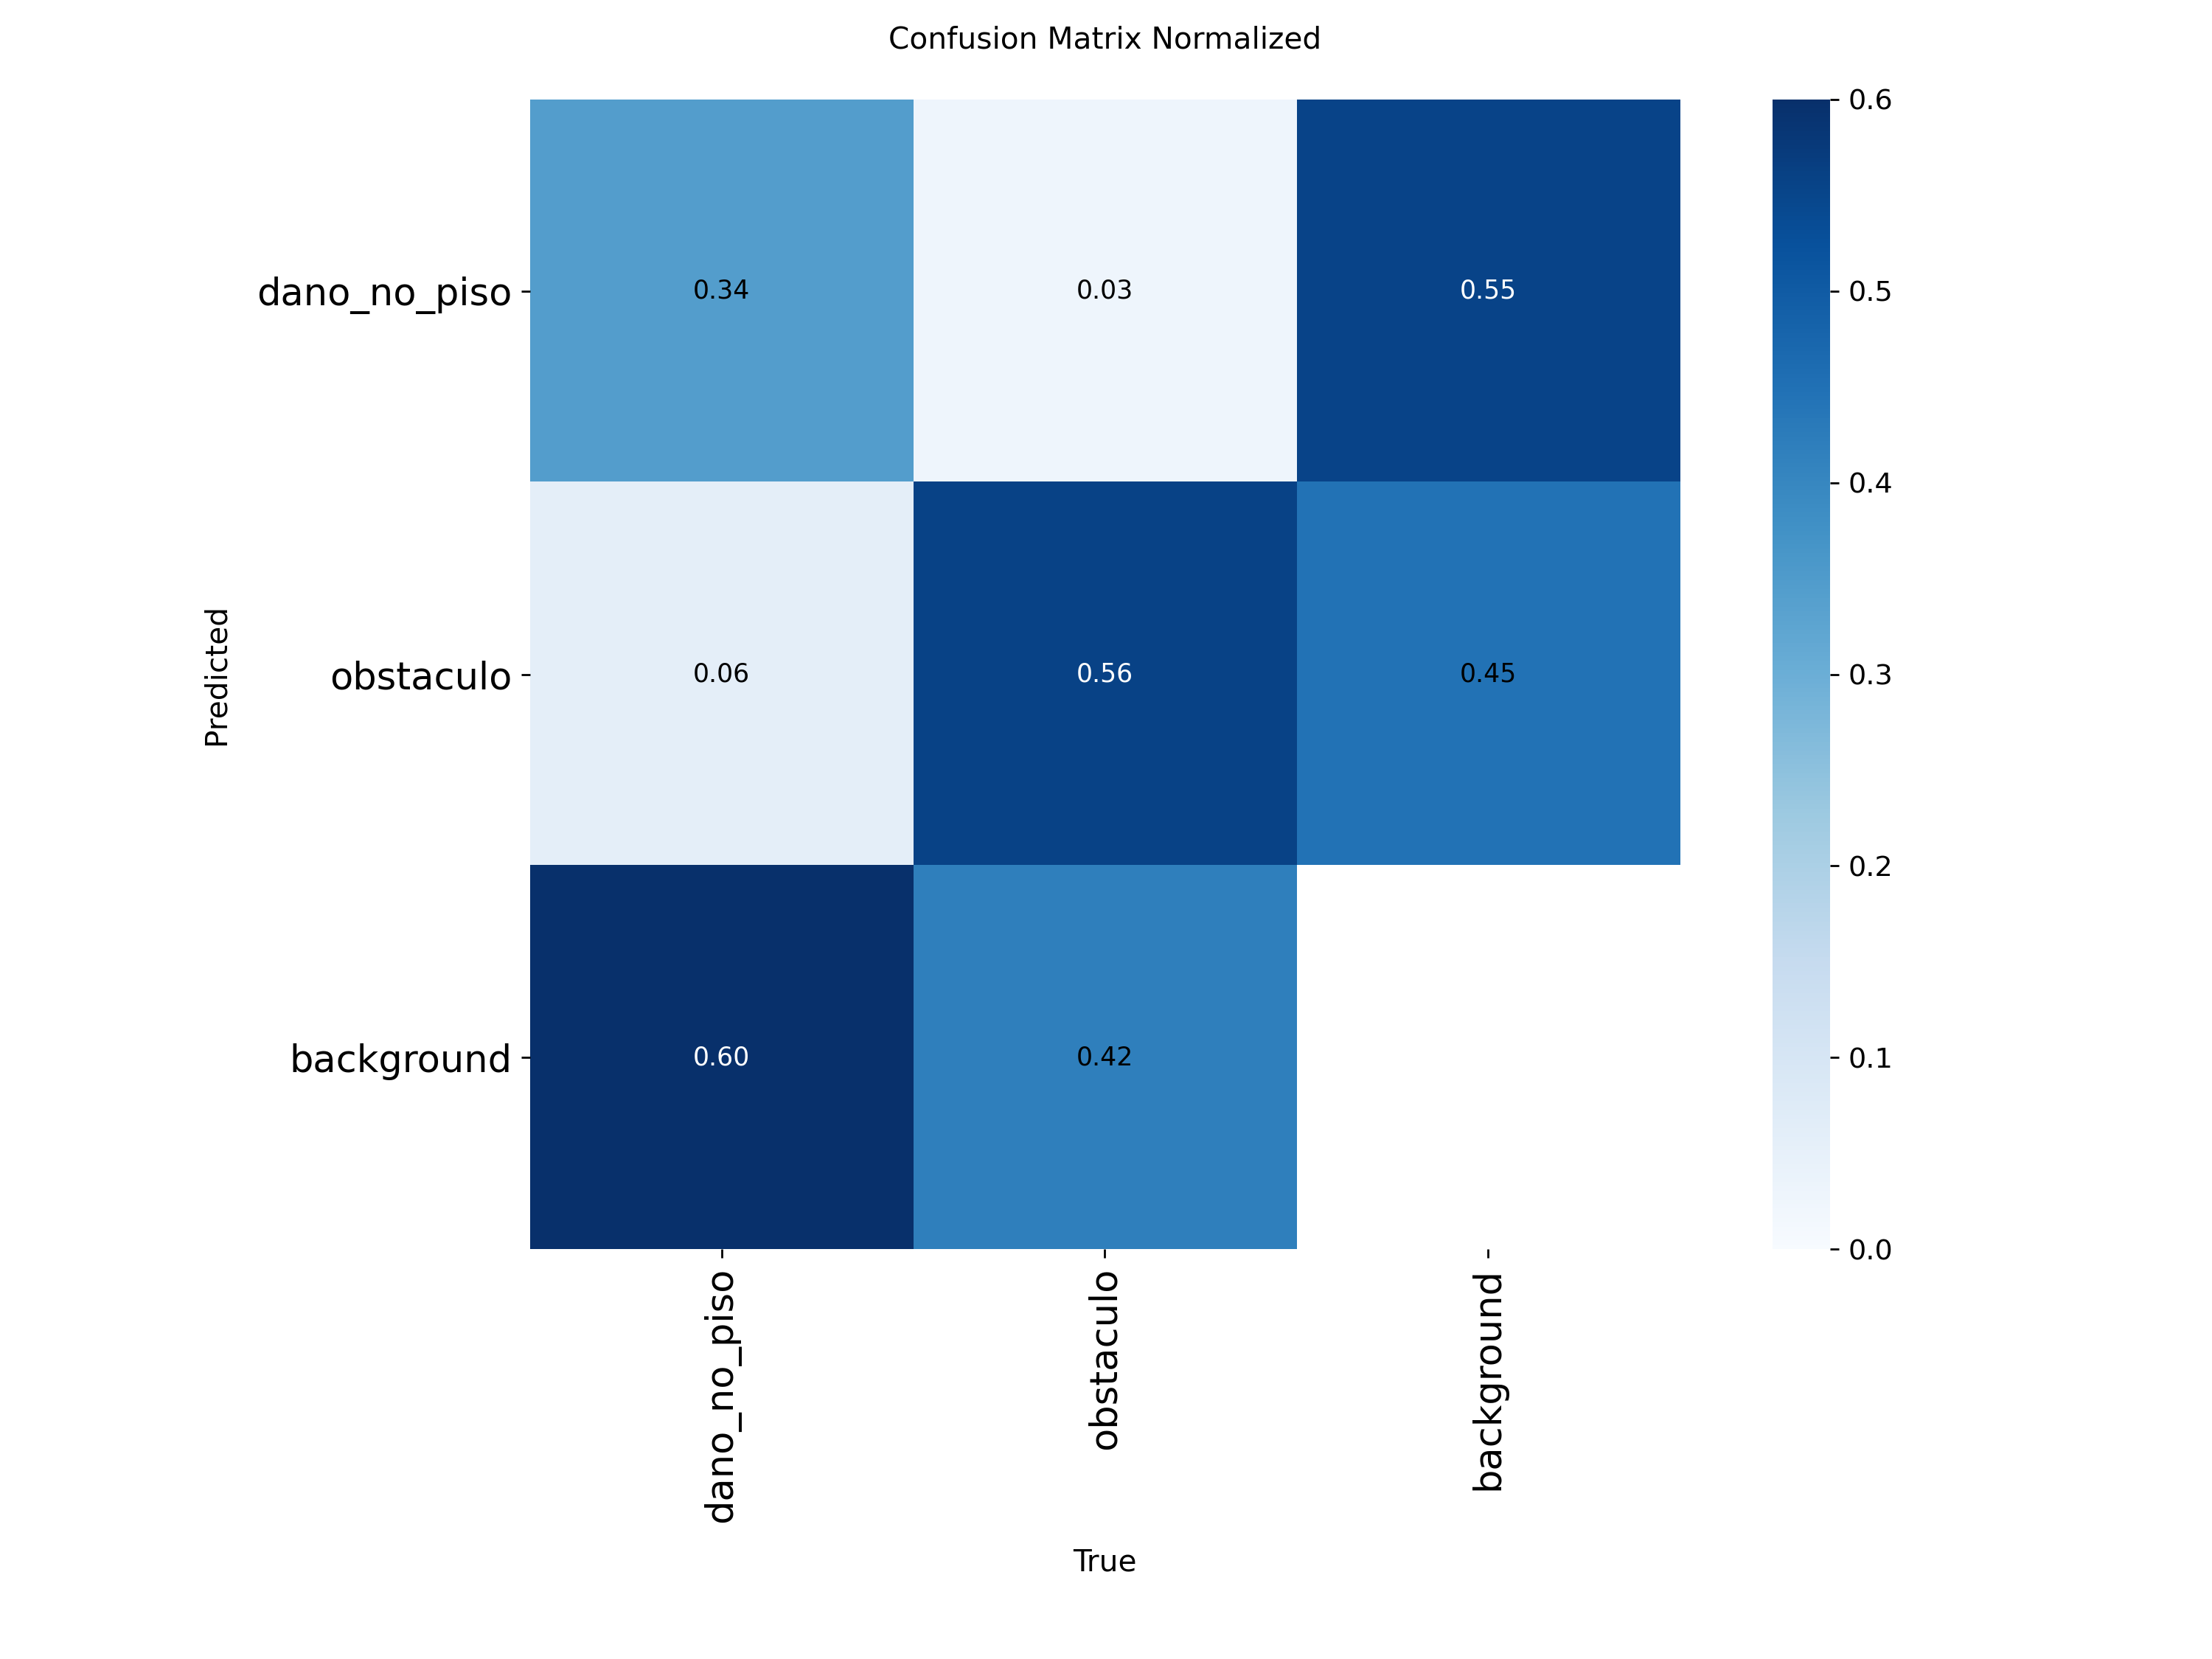

In [12]:
import glob
for nome in ["A_teste", "C2_teste"]:
    for f in sorted(glob.glob(f"/content/runs/{nome}/confusion_matrix_normalized.png")):
        print(nome)
        display(Image(f, width=650))

## 5. Experimento B — YOLO26s (comparação de tamanho)

Mesmo dataset de 3 classes, mesma resolução, modelo maior. Mostra no PDF a troca entre precisão e velocidade e justifica a escolha do nano para o tempo real.

In [13]:
YOLO("yolo26s.pt").train(data=DATA, name="B_yolo26s", **comum)
B_BEST = "/content/runs/B_yolo26s/weights/best.pt"
tabelaB, geralB = avaliar(B_BEST, "B_teste", DATA)

comparacao = pd.DataFrame([{"modelo": "YOLO26n 3 classes (A)", **geralA},
                           {"modelo": "YOLO26n 2 classes (C2)", **geralC2},
                           {"modelo": "YOLO26s 3 classes (B)", **geralB}]).round(3)
comparacao   # vai para o PDF

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=B_yolo26s, nbs=64, nms=None, opset=None, optimize=False, optim

,modelo,precisão,recall,mAP50,mAP50-95,ms por imagem (GPU T4)
0,YOLO26n 3 classes (A),0.149,0.199,0.107,0.050,8.211
1,YOLO26n 2 classes (C2),0.271,0.210,0.169,0.097,4.072
2,YOLO26s 3 classes (B),0.404,0.164,0.167,0.071,5.583


## 6. Desempenho por grupo de imagens (IA responsável)

O detector acerta igual nas calçadas de São Paulo e nas do dataset aberto? Compara o teste (só SP) com a reserva do dataset aberto, que não entrou no treino nem na escolha do modelo. Grupos com menos de ~30 imagens dão números instáveis, e o relatório os lê com cautela.

In [14]:
import tempfile

def avaliar_lista(pesos, imagens, nomes_classes):
    pasta = Path(tempfile.mkdtemp())
    (pasta / "lista.txt").write_text("\n".join(map(str, imagens)))
    (pasta / "grupo.yaml").write_text(yaml.safe_dump(
        {"path": str(pasta), "train": str(pasta / "lista.txt"), "val": str(pasta / "lista.txt"), "names": nomes_classes},
        allow_unicode=True))
    m = YOLO(pesos).val(data=str(pasta / "grupo.yaml"), split="val", imgsz=IMG, plots=False, verbose=False)
    return {"precisão": m.box.mp, "recall": m.box.mr, "mAP50": m.box.map50, "mAP50-95": m.box.map}

grupos = {
    "SP (teste)": sorted((Path(dataset.location) / "test" / "images").glob("*")),
    "dataset aberto (reserva)": sorted((Path(dataset.location) / "aberto_reserva" / "images").glob("*")),
}
por_grupo = pd.DataFrame([{"grupo": g, "imagens": len(lista), **avaliar_lista(A_BEST, lista, cfg["names"])}
                          for g, lista in grupos.items() if lista]).round(3)
por_grupo   # vai para o PDF

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3733.3±1589.7 MB/s, size: 329.5 KB)
val: Scanning /content/dataset/test/labels.cache... 31 images, 5 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 31/31 5.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.5it/s 0.8s
                   all         31         71      0.149      0.199      0.107     0.0497
Speed: 1.0ms preprocess, 3.6ms inference, 0.0ms loss, 2.5ms postprocess per image
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 23.5±36.4 MB/s, size: 424.3 KB). Use local storage instead of remote/mounted storage for 

,grupo,imagens,precisão,recall,mAP50,mAP50-95
0,SP (teste),31,0.149,0.199,0.107,0.050
1,dataset aberto (reserva),16,0.941,0.833,0.893,0.636


## 7. Exemplos de resultados e análise de erros

Compara, imagem a imagem do teste, as caixas anotadas (verde) com as previstas (vermelho). Acerto = mesma classe e IoU ≥ 0,5. Os piores casos alimentam a análise de erros do relatório; os melhores viram as figuras de exemplo.

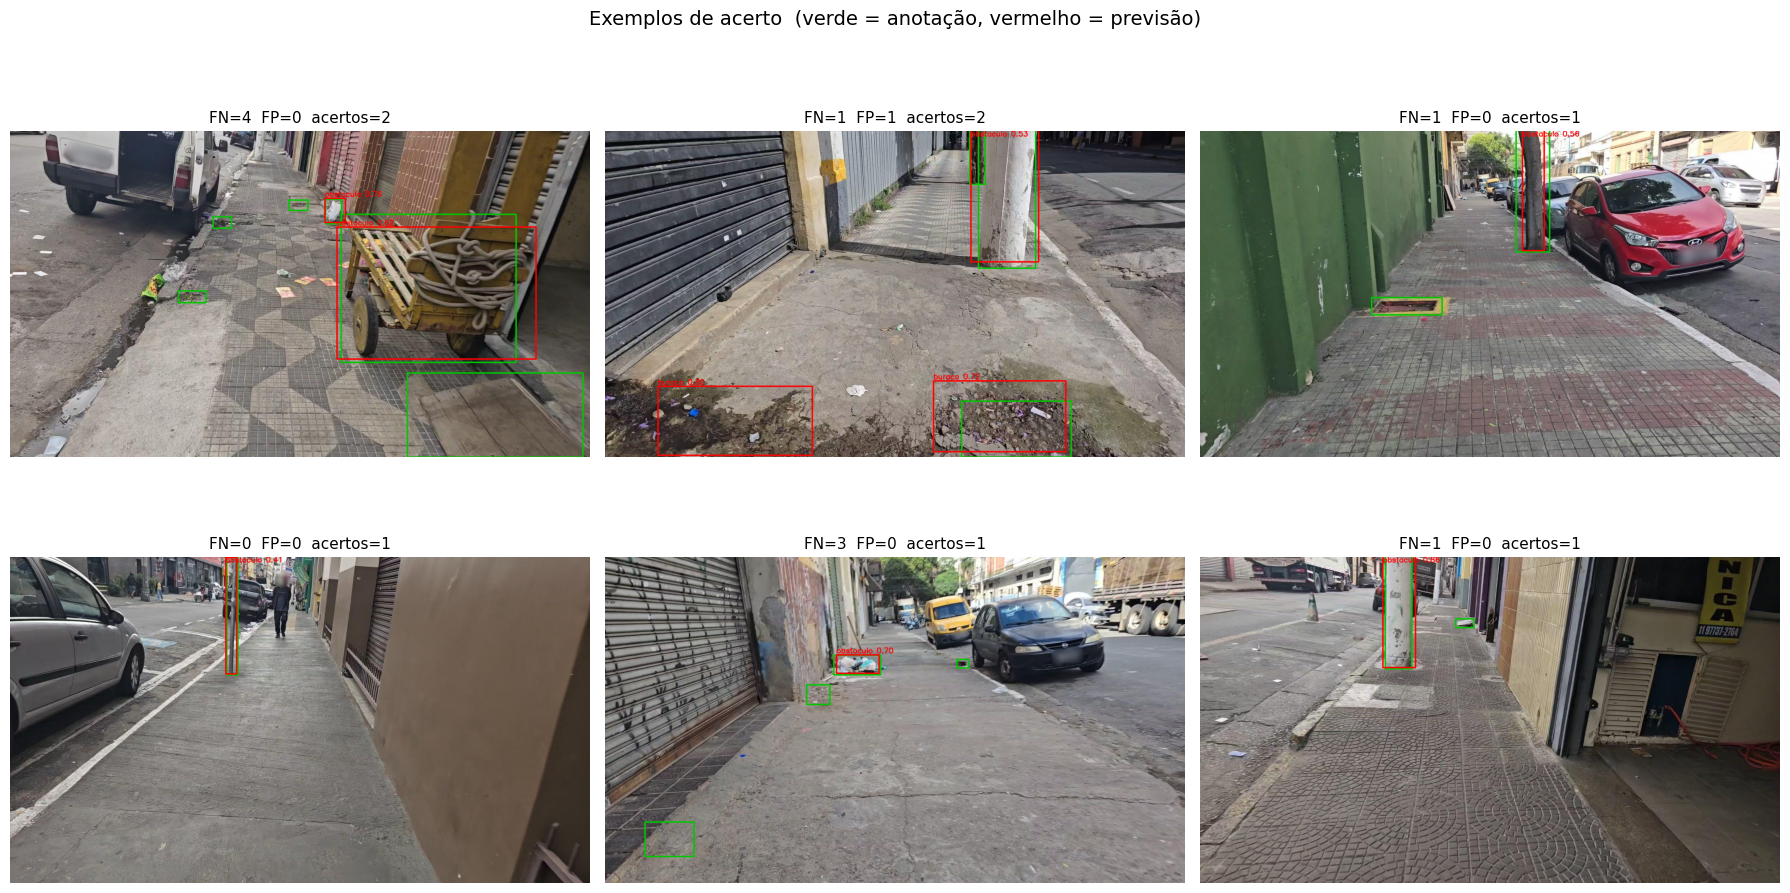

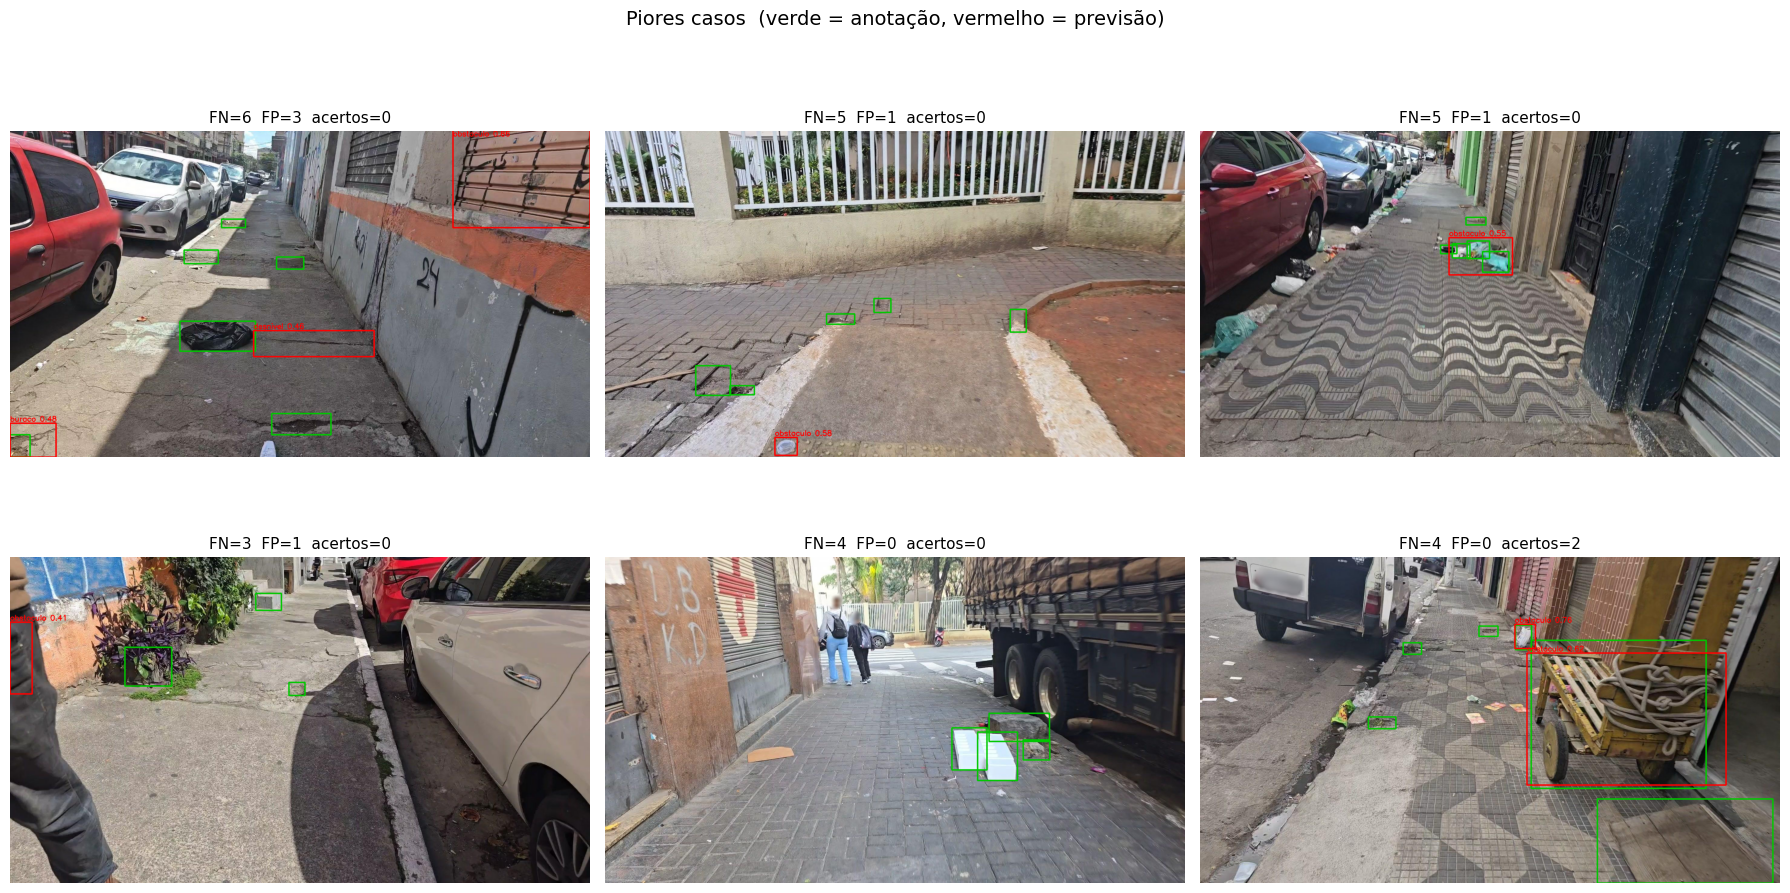

,0
anotadas,71
previstas,27
acertos,10
falsos negativos,61
falsos positivos,17


In [15]:
import cv2
import matplotlib.pyplot as plt

MELHOR = A_BEST   # troque por C2_BEST se a variante de 2 classes for a escolhida
melhor = YOLO(MELHOR)
pasta_img = Path(dataset.location) / PASTA_TESTE / "images"
pasta_lbl = Path(dataset.location) / PASTA_TESTE / "labels"

def caixas_reais(img_path, w, h):
    f = pasta_lbl / (img_path.stem + ".txt")
    caixas = []
    if f.exists():
        for l in f.read_text().splitlines():
            if l.strip():
                c, xc, yc, bw, bh = map(float, l.split()[:5])
                caixas.append((int(c), (xc - bw / 2) * w, (yc - bh / 2) * h, (xc + bw / 2) * w, (yc + bh / 2) * h))
    return caixas

def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    uniao = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / uniao if uniao > 0 else 0

casos = []
for p in sorted(pasta_img.glob("*")):
    r = melhor.predict(str(p), conf=0.35, imgsz=IMG, verbose=False)[0]
    h, w = r.orig_shape
    reais = caixas_reais(p, w, h)
    previstas = [(int(c), *xyxy) for xyxy, c in zip(r.boxes.xyxy.tolist(), r.boxes.cls.tolist())]
    usadas = set()
    for real in reais:
        for j, prev in enumerate(previstas):
            if j not in usadas and prev[0] == real[0] and iou(real[1:], prev[1:]) >= 0.5:
                usadas.add(j)
                break
    casos.append({"imagem": p.name, "anotadas": len(reais), "previstas": len(previstas), "acertos": len(usadas),
                  "falsos negativos": len(reais) - len(usadas), "falsos positivos": len(previstas) - len(usadas),
                  "_r": r, "_reais": reais})

def painel(lista, titulo, arquivo):
    fig, eixos = plt.subplots(2, 3, figsize=(18, 10))
    for ax in eixos.flat:
        ax.axis("off")
    for ax, caso in zip(eixos.flat, lista):
        img = caso["_r"].orig_img.copy()
        for c, x1, y1, x2, y2 in caso["_reais"]:
            cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), (0, 200, 0), 4)
        for xyxy, c, cf in zip(caso["_r"].boxes.xyxy.tolist(), caso["_r"].boxes.cls.tolist(), caso["_r"].boxes.conf.tolist()):
            x1, y1, x2, y2 = map(int, xyxy)
            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 0, 255), 3)
            cv2.putText(img, f"{caso['_r'].names[int(c)]} {cf:.2f}", (x1, max(20, y1 - 6)), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2)
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(f"FN={caso['falsos negativos']}  FP={caso['falsos positivos']}  acertos={caso['acertos']}", fontsize=11)
    fig.suptitle(titulo + "  (verde = anotação, vermelho = previsão)", fontsize=14)
    plt.tight_layout()
    plt.savefig(arquivo, dpi=110)
    plt.show()

bons = sorted(casos, key=lambda c: (c["acertos"], -c["falsos positivos"]), reverse=True)[:6]
piores = sorted(casos, key=lambda c: c["falsos negativos"] + c["falsos positivos"], reverse=True)[:6]
painel(bons, "Exemplos de acerto", "/content/runs/exemplos_acerto.png")
painel(piores, "Piores casos", "/content/runs/piores_casos.png")

resumo_erros = pd.DataFrame([{k: v for k, v in c.items() if not k.startswith("_")} for c in casos])
resumo_erros.sum(numeric_only=True)

A análise dos piores casos do modelo final, agrupada em três padrões de erro, está no relatório, na seção de resultados.

## 8. Velocidade em CPU

O tempo real roda no computador do grupo, sem GPU. Esta medida na CPU do Colab dá uma ideia; a medida do relatório sai do `src/tempo_real.py` rodando no PC do grupo (14,5 FPS com a webcam num AMD Ryzen 5 2600).

In [16]:
import time

amostra = sorted(pasta_img.glob("*"))[:30]
velocidade = []
for nome, pesos in [("YOLO26n 3 classes (A)", A_BEST), ("YOLO26n 2 classes (C2)", C2_BEST)]:
    modelo_cpu = YOLO(pesos)
    modelo_cpu.predict(str(amostra[0]), device="cpu", imgsz=IMG, verbose=False)   # aquecimento
    inicio = time.perf_counter()
    for p in amostra:
        modelo_cpu.predict(str(p), device="cpu", imgsz=IMG, verbose=False)
    ms = (time.perf_counter() - inicio) / len(amostra) * 1000
    velocidade.append({"modelo": nome, "ms por imagem (CPU do Colab)": round(ms), "FPS aproximado": round(1000 / ms, 1)})
velocidade = pd.DataFrame(velocidade)
velocidade   # o FPS do relatório sai do tempo_real.py no PC do grupo

,modelo,ms por imagem (CPU do Colab),FPS aproximado
0,YOLO26n 3 classes (A),75,13.3
1,YOLO26n 2 classes (C2),72,13.8


## 9. Baixar os resultados

Baixa três arquivos para a pasta Downloads do computador:
- `best_3classes.pt` (A) e `best_2classes.pt` (C2): os dois modelos. O escolhido vai para `modelos/best.pt` no repositório.
- `resultados_rodada2.zip`: gráficos, matrizes de confusão, painéis de acertos e erros e as tabelas em CSV.

Se o navegador perguntar se o Colab pode baixar vários arquivos, permitam.

In [17]:
from google.colab import files

pasta_tabelas = Path("/content/runs/tabelas")
pasta_tabelas.mkdir(parents=True, exist_ok=True)
for nome, tabela in [("dataset", tabela_dataset), ("teste_por_classe_A", tabelaA), ("teste_por_classe_C2", tabelaC2),
                     ("A_x_C2_duas_classes", comparacao_classes), ("comparacao_modelos", comparacao),
                     ("por_grupo", por_grupo), ("velocidade_cpu", velocidade)]:
    tabela.to_csv(pasta_tabelas / f"{nome}.csv", index=False)

shutil.copy(A_BEST, "/content/best_3classes.pt")
shutil.copy(C2_BEST, "/content/best_2classes.pt")
shutil.make_archive("/content/resultados_rodada2", "zip", "/content/runs")
files.download("/content/best_3classes.pt")
files.download("/content/best_2classes.pt")
files.download("/content/resultados_rodada2.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Onde estes resultados aparecem no relatório

| Seção do PDF | O que levar |
| --- | --- |
| Metodologia | `tabela_dataset`, tabela de hiperparâmetros (seção 3), `results.png`, e por que a validação passou a ser só de SP (rodada 1) |
| Resultados | `tabelaA` (por classe), `comparacao_classes` (3 × 2 classes), `comparacao` (n × s), matriz de confusão normalizada, `exemplos_acerto.png` |
| Tempo real | `velocidade` (seção 8) e o FPS medido com o `tempo_real.py` |
| IA responsável | `por_grupo` (SP × dataset aberto) |
| Análise de erros | `piores_casos.png` e os três padrões de erro comentados |

## Resumo desta execução (rodada 2, 16/11/2026)

- **Validação só com São Paulo** (22 fotos); as 16 fotos do dataset aberto que estavam nela ficaram de reserva, fora do treino e da escolha da época.
- **Teste (31 fotos de SP):** A (3 classes) com mAP50 de 0,107; C2 (2 classes) com 0,169; B (YOLO26s, 3 classes) com 0,167.
- **Juntar buraco e desnível não ajudou:** `dano_no_piso` ficou em 0,033 no C2, e o próprio A, avaliado juntando as duas classes, em 0,060.
- **SP × dataset aberto:** o mesmo modelo A tem mAP50 de 0,107 nas fotos de SP e de 0,893 nas 16 fotos abertas que nunca viu. É o principal achado de IA responsável do trabalho: dado local faz diferença.
- **Modelo final do projeto:** continua o A da rodada 1 (`modelos/best.pt`). No teste, as duas rodadas ficaram na mesma margem para 31 imagens; ao vivo, o C2 oscilava em torno de 0,26 numa lixeira que o A da rodada 1 marcava com 0,90 (detalhes no relatório).